<a href="https://colab.research.google.com/github/rajbhavel98-crypto/DA-project3/blob/main/DA_project3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

d = {
    "ID" : [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25],
    "Name" : ["Raj","animesh","lucky","kartik","vani","neha","rajat","yash",None,"dfkjb","sneha",None,"Raj","rahul","gulshan","prachi","neha","john","renuka",None,"prince","None","dask","khushi",None,],
    "Designation" : ["ai engineer","ai engineer","Devops","development","coordinator","recruiter","sales","compounder",None,None,"","autorikshaw","admin","sales","R&d executive","recruiter","admin",None,"receptionist","sales",None,"recruiter",None,"receptionist","sales"],
    "Dept" : ["IT","IT","IT","HR","HR","HR","marketing",None,"finance","HR","marketing",None,"Marketing","marketing",None,"marketing","IT","HR","IT",None,"","HR",None,"HR","marketing"],
    "salary" : [30000,27500,32300,25800,22050,28000,15000,10000,None,60000,28700,40000,50000,None,55600,39500,30000,59600,None,35600,18000,None,26400,34300,25000],
    "variables" : [5000,5000,5000,3500,None,0,1500,150,None,7500,12300,30000,None,0,1500,4900,None,10000,3500,4500,4000,None,2200,-10000,None],
    "city" : ["banglore","Indore","Hyderabad","Pune","Indore","Delhi","Bihar","Indore","delhi","Banglore","Pune",None,"Mumbai","delhi",None,"Indore","Banglore","Mumbai","hyderabad","Bihar",None,"banglore","Pune","Delhi",None],
    "gmail" : ["gmail" ,  "animesh@" , "Lucky@gmail.com" , "vani@gmail.com" , "vani@yahoo.com" , "neha@47gmail" , None , "compounder@gmail.com" , "pari@gmail.com" , "rocky@gmail.com", "neha@" , None , "raj@gmail.com" , "parul@gmail.com" , "gulshan@yahoo.com" , None , "sneha@gmail.com" , "@gmail.com" , None , "varun@gmail.com" , "vishal@" , "ishana@gmail.com" , "daksh@yahoo.com" , "None" , "Khushi@gmail.com"]
}

cpy = pd.DataFrame(d)
df = pd.DataFrame(d)

In [ ]:
df['email'] = ("@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com","@gmail.com")

In [ ]:
df['email'] = df['Name'] + df['email']

In [ ]:
# df['Name'] = df['Name'].fillna(df['gmail'].str.split('@').str[0])
# df

In [ ]:
for i in df.index:
  if pd.isna(df['email'])[i] or df['email'][i] == "None":
    df['email'][i] = df['gmail'][i]

/tmp/ipykernel_1095/2687577981.py:3: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['email'][i] = df['gmail'][i]
/tmp/ipykernel_1095/2687577981.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFram

In [ ]:
for i in df.index:
  if pd.isna(df['Name'])[i] or df['Name'][i] == "None":
    df['Name'] = df['email'].str.split('@').str[0]

In [ ]:
df.dropna(subset=['Name', 'email'], how='all', inplace=True)

In [ ]:
# # df['Name'] = df['Name'].fillna(df['gmail'].str.split('@').str[0])
# # df

# for i in df.index:
#   if pd.isna(df['Name'])[i] or df['Name'][i] == "None":
#     df['Name'] = df['email'].str.split('@').str[0]

# df

In [ ]:
df['Name'] = df['Name'].str.capitalize()
df['Designation'] = df['Designation'].str.capitalize()
df['Dept'] = df['Dept'].str.upper()
df['city'] = df['city'].str.capitalize()
df['email'] = df['email'].str.lower()

In [ ]:
df.drop(columns=['gmail'] , axis=1 , inplace=True)

In [ ]:
# for i in df.index:
#   if pd.isna(df['Designation'])[i] or df['Desgination'][i] == "None":
#     df['Designation'][i] = "unknown"

df.loc[
    df['Designation'].isna() | (df['Designation'] == "None")| (df['Designation'] == ""),
    'Designation'
] = "Unknown"

In [ ]:
df.loc[
    df['Dept'].isna() | (df['Dept'] == "None")| (df['Dept'] == ""),
    'Dept'
] = "Unknown"

In [ ]:
df.loc[
    df['city'].isna() | (df['city'] == "None")| (df['city'] == ""),
    'city'
] = "Unknown"

In [ ]:
df['salary'] = df['salary'].fillna(np.mean(df['salary']))

In [ ]:
df['variables'] = np.abs(df['variables'])

In [ ]:
df['variables'] = df['variables'].fillna(np.mean(df['variables']))

In [ ]:
df.insert(6,"Tax" , np.where(df['salary'] + df['variables'] >= 50000 , (df['salary'] + df['variables'])/10 , 0))

In [ ]:
df.insert(7,"SAT" , (df['salary'] + df['variables'] - df['Tax']))

In [ ]:
UD = df.query('Dept == "Unknown"')

In [ ]:
df

,ID,Name,Designation,Dept,salary,variables,Tax,SAT,city,email
0,1,Raj,Ai engineer,IT,30000.0,5000.0,0.0,35000.0,Banglore,raj@gmail.com
1,2,Animesh,Ai engineer,IT,27500.0,5000.0,0.0,32500.0,Indore,animesh@gmail.com
2,3,Lucky,Devops,IT,32300.0,5000.0,0.0,37300.0,Hyderabad,lucky@gmail.com
3,4,Kartik,Development,HR,25800.0,3500.0,0.0,29300.0,Pune,kartik@gmail.com
4,5,Vani,Coordinator,HR,22050.0,4475.0,0.0,26525.0,Indore,vani@gmail.com
5,6,Neha,Recruiter,HR,28000.0,0.0,0.0,28000.0,Delhi,neha@gmail.com
6,7,Rajat,Sales,MARKETING,15000.0,1500.0,0.0,16500.0,Bihar,rajat@gmail.com
7,8,Yash,Compounder,Unknown,10000.0,150.0,0.0,10150.0,Indore,yash@gmail.com
8,9,Pari,Unknown,FINANCE,32667.5,4475.0,0.0,37142.5,Delhi,pari@gmail.com
9,10,Dfkjb,Unknown,HR,60000.0,7500.0,6750.0,60750.0,Banglore,dfkjb@gmail.com


In [ ]:
c = [
    'red',
    'blue',
    'green',
    'yellow',
    'orange',
    'purple',
    'pink',
    'cyan',
    'magenta',
    'lime',
    'brown',
    'black',
    'gray',
    'gold',
    'coral',
    'salmon',
    'teal',
    'navy',
    'indigo',
    'violet',
    'turquoise',
    'chocolate',
    'crimson',
    'olive',
    'orchid'
]

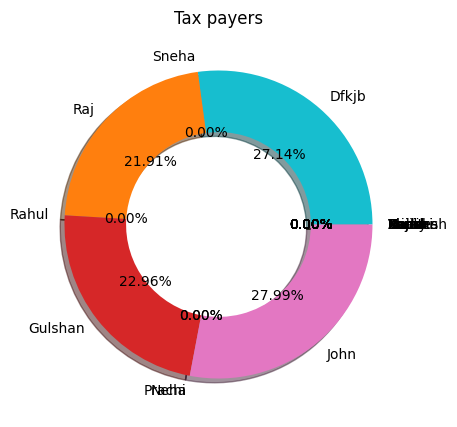

In [ ]:
plt.figure(figsize=(10,5))

x = df['Tax']
l = df['Name']

plt.pie(x,
        autopct="%.2f%%",
        labels=l,
        wedgeprops={'width' : 0.4},
        shadow=10)
plt.title("Tax payers")
plt.show()

In [ ]:
plt.figure(figsize=(10,5))
n = df['Name']
x = df['salary']
y = df['variables']

plt.stackplot(n,x,y,
              )
plt.title("CTC")
plt.xlabel("x-axis")
plt.ylabel("y-axis")
plt.grid()
plt.show()

In [ ]:
x = df['city']

plt.hist(x,
         bins=8,
         color="r",
         edgecolor="black")
plt.title("City")
plt.xlabel("x-axis")
plt.ylabel("y-axis")
plt.grid()
plt.show()

In [ ]:
x = df['Dept']

plt.hist(x,
         bins=5,
         color="yellow",
         edgecolor="red")
plt.title("Dept")
plt.xlabel("x-axis")
plt.ylabel("y-axis")
plt.grid()
plt.show()

In [ ]:
c = [
    'red',
    'blue',
    'green',
    'yellow',
    'orange',
    'purple',
    'pink',
    'brown',
    'black',
    'white',
    'cyan',
    'magenta',
    'lime',
    'navy',
    'teal',
    'coral',
    'gold',
    'indigo',
    'violet',
    'salmon',
    'crimson',
    'turquoise',
    'olive',
    'orchid',
    'skyblue'
]

In [ ]:
from matplotlib import colors
plt.figure(figsize=(22,8))
n = df['Name']
s = df['SAT']
t = df['Tax']

plt.bar(n,s,
        color=c,
        edgecolor="black",
        label=n)
plt.stem(s,
         linefmt="r--",
         markerfmt="b^",
         basefmt="blue")

plt.title("Emp Data")
plt.xlabel("x-axis")
plt.ylabel("y-axis")
plt.legend(loc="upper left")
plt.grid()
plt.show()
